<a href="https://colab.research.google.com/github/Vitela-debug/Colab_S1_Clase-de-progralaci-n_273522_TVB/blob/main/Vitela_Tania_EDA_predictivo.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Actividad: análisis exploratorio de datos para analítica predictiva
## Caso: suscripción a un depósito a plazo tras una llamada de telemarketing bancario

Programación para Analítica Descriptiva y Predictiva · Tema : EDA con Analítica Predictiva
Maestría en Inteligencia Artificial y Analítica de Datos · UACJ

**Nombre del estudiante:** __Tania Vitela Barraza__  

**Matrícula:**__23522__

**Fecha:** __10/11/2026__

## Propósito

Aplicar, de forma individual y sobre un conjunto de datos nuevo, el procedimiento de análisis exploratorio para analítica predictiva revisado en el notebook guiado del caso Telco. El producto de la actividad es una **hoja de decisiones** de preprocesamiento y modelado, sustentada en evidencia obtenida con el código.

No se entrena ningún modelo en esta actividad.

## Instrucciones de entrega

1. Completa las celdas de código y las de texto marcadas con **Tu predicción**, **Tu observación** o **Tu respuesta**.
2. Antes de entregar, ejecuta el notebook completo con *Kernel > Restart & Run All*. El notebook debe ejecutarse de principio a fin sin errores.
3. Guarda el archivo como `Apellido_Nombre_EDA_predictivo.ipynb` y entrégalo en el medio indicado por el profesor.
4. La actividad es individual. Las predicciones deben escribirse **antes** de ejecutar cada celda de código.

## Reglas de trabajo

- Usa solo el conjunto `df` y las librerías ya importadas.
- Después de la división de la parte C, el conjunto `prueba` **no se utiliza** en ninguna celda.
- Usa `random_state=42` en toda operación aleatoria, para que los resultados sean comparables.
- Las observaciones y las decisiones citan cifras obtenidas con tu propio código.

## Conjunto de datos y fuente

**Bank Marketing** (archivo `bank-additional-full.csv`), del repositorio UCI de aprendizaje automático. Cada fila es un contacto telefónico de una campaña de marketing directo de un banco portugués. El conjunto contiene 41,188 contactos ordenados por fecha, de mayo de 2008 a noviembre de 2010, y 21 columnas.


**Problema predictivo.** Clasificación binaria: dadas las características de un cliente y del contexto de la campaña, predecir si el cliente contratará el depósito a plazo (`y`).

**Diccionario de datos**

| Columna | Contenido |
| --- | --- |
| `age` | Edad del cliente |
| `job`, `marital`, `education` | Ocupación, estado civil y escolaridad |
| `default`, `housing`, `loan` | Si tiene crédito en incumplimiento, crédito hipotecario y préstamo personal |
| `contact` | Medio de contacto: `cellular` o `telephone` |
| `month`, `day_of_week` | Mes y día de la semana del último contacto de la campaña actual |
| `duration` | Duración de la última llamada, en segundos |
| `campaign` | Número de contactos con este cliente en la campaña actual, incluido el último |
| `pdays` | Días transcurridos desde el último contacto de una campaña anterior; `999` indica que no fue contactado antes |
| `previous` | Número de contactos antes de la campaña actual |
| `poutcome` | Resultado de la campaña anterior: `success`, `failure` o `nonexistent` |
| `emp.var.rate`, `cons.price.idx`, `cons.conf.idx`, `euribor3m`, `nr.employed` | Indicadores económicos trimestrales o mensuales: variación del empleo, índice de precios, índice de confianza del consumidor, tasa Euribor a 3 meses y número de empleados |
| `y` | Variable objetivo: `yes` si el cliente contrató el depósito, `no` si no |

## 1. Preparación del entorno y carga de datos (celda proporcionada)

Ejecuta la celda sin modificarla. Si el archivo no está en la carpeta, la celda lo descarga de una copia pública del conjunto; si ya está, lo reutiliza. El archivo usa punto y coma como separador.

In [1]:
import os
import urllib.request

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split

sns.set_theme(style="whitegrid")
AZUL = "#1E2761"
NARANJA = "#D98E04"
COLORES_CLASE = {"no": AZUL, "yes": NARANJA}
pd.set_option("display.max_columns", 25)
pd.set_option("display.width", 120)

url = "https://raw.githubusercontent.com/selva86/datasets/master/bank-additional-full.csv"
archivo = "bank_marketing.csv"

if not os.path.exists(archivo):
    urllib.request.urlretrieve(url, archivo)

df = pd.read_csv(archivo, sep=";")

numericas = ["age", "duration", "campaign", "pdays", "previous",
             "emp.var.rate", "cons.price.idx", "cons.conf.idx", "euribor3m", "nr.employed"]
categoricas = ["job", "marital", "education", "default", "housing", "loan",
               "contact", "month", "day_of_week", "poutcome"]
macro = ["emp.var.rate", "cons.price.idx", "cons.conf.idx", "euribor3m", "nr.employed"]

print("Filas y columnas:", df.shape)

Filas y columnas: (41188, 21)


## Parte A. Definición del problema

**Por qué.** Un EDA predictivo se orienta por preguntas que se responden antes de calcular nada. Una de ellas, qué información estará disponible al momento de predecir, decide qué variables pueden entrar al modelo.

Completa la columna **Respuesta** de la siguiente tabla, editando esta celda.

| Pregunta | Respuesta |
| --- | --- |
| ¿Qué es una observación? | Cada fila representa un contacto telefónico realizado a un cliente durante una campaña de marketing directo de un banco portugués. |
| ¿Qué se predice? |  Si el cliente contratará un depósito a plazo, representado por la variable objetivo y, con valores yes o no.|
| ¿Qué tipo de problema es? | De clasificación binaria, porque se busca predecir una de dos categorías posibles.|
| ¿En qué momento se haría la predicción y qué información existiría entonces? | información existiría entonces?	La predicción se realizaría antes de contactar al cliente o antes de iniciar la llamada de la campaña actual. Se dispondría de sus características personales, información crediticia, historial de campañas anteriores e indicadores económicos disponibles en ese momento, pero no del resultado ni de la duración de la llamada actual. |
| ¿Qué columnas no deberían usarse como características y por qué? | La variable `y` no debe utilizarse como característica porque es el objetivo que se quiere predecir. La variable `duration `tampoco debería utilizarse si la predicción se hace antes de la llamada, ya que solo se conoce después de realizarla. Además, debe evitarse cualquier información que se obtenga después del momento de predicción, porque provocaría fuga de información|

**Tu predicción.** ¿Qué porcentaje de los contactos esperas que haya terminado en contratación del depósito?


Mi predicción inicial es que aproximadamente el 30 % de los contactos terminó en la contratación del depósito a plazo.

## Parte B. Descripción de los datos y detección de problemas de calidad, conjunto total

**Por qué.** La descripción (tamaño, tipos, significado de las columnas) y la detección de problemas con criterios estructurales o del dominio no usan la variable objetivo ni calculan parámetros que se aplicarán al modelo. Por eso se hacen con el conjunto total `df`, antes de dividir. Esta parte **detecta y cuantifica**; las decisiones de tratamiento se toman en la hoja de la parte G.

Las verificaciones de calidad de CRISP-DM que se piden son: consistencia de valores, cantidad y distribución de valores nulos, y valores fuera de rango.

**Pista.** En este conjunto los faltantes en variables categóricas se codifican con el texto `unknown`, no con `NaN`.

**Tu predicción.** ¿Habrá valores `NaN`? ¿En qué columnas esperas encontrar `unknown` y en cuántas filas?

Mi predicción es que si podría haber valores `NaN`, aunque espero que sean muy pocos, porque los datos faltantes de este conjunto se representan principalmente con la categoría unknown.

Espero encontrar valores unknown en las columnas categóricas job, marital, education, default, housing y loan. También podrían aparecer en otras variables categóricas si existen registros sin información.

Sabiendo que el conjunto contiene 41,188 contactos, estimo que unknown aparecerá en varias filas, especialmente en las variables relacionadas con la información crediticia y el nivel educativo. La cantidad exacta deberá comprobarse mediante el análisis de calidad de los datos.

In [2]:
# B1. Estructura. Escribe el código que muestre:
#  - las dimensiones del conjunto,
#  - el tipo de dato de cada columna,
#  - el número de valores únicos por columna, de menor a mayor.

# 1. Dimensiones del conjunto
print("Dimensiones del conjunto de datos:")
print(f"Filas: {df.shape[0]:,}")
print(f"Columnas: {df.shape[1]}")

# 2. Tipo de dato de cada columna
print("\nTipo de dato de cada columna:")
print(df.dtypes)

# 3. Número de valores únicos por columna, de menor a mayor
print("\nValores únicos por columna (de menor a mayor):")
print(df.nunique().sort_values(ascending=True))



Dimensiones del conjunto de datos:
Filas: 41,188
Columnas: 21

Tipo de dato de cada columna:
age                 int64
job                object
marital            object
education          object
default            object
housing            object
loan               object
contact            object
month              object
day_of_week        object
duration            int64
campaign            int64
pdays               int64
previous            int64
poutcome           object
emp.var.rate      float64
cons.price.idx    float64
cons.conf.idx     float64
euribor3m         float64
nr.employed       float64
y                  object
dtype: object

Valores únicos por columna (de menor a mayor):
contact              2
y                    2
default              3
loan                 3
poutcome             3
housing              3
marital              4
day_of_week          5
previous             8
education            8
emp.var.rate        10
month               10
nr.employed         11


---
---
* El código del ejercicio B1 muestra las filas y columnas (`df.shape`), `df.dtypes` indica los tipos de datos y `df.nunique().sort_values()` cuenta y ordena los valores únicos de menor a mayor.

---
---


In [3]:
# B2. Valores faltantes. Escribe el código que muestre:
#  - el total de valores NaN del conjunto,
#  - para las columnas categóricas, cuántas filas tienen "unknown" (solo las columnas con al menos una),
#  - ese conteo como porcentaje de las filas.

# 1. Total de valores NaN
print("Total de valores NaN:", df.isna().sum().sum())

# 2. Conteo de "unknown" en columnas categóricas
categoricas = df.select_dtypes(include="object")
unknown = (categoricas == "unknown").sum()
unknown = unknown[unknown > 0]

print("\nColumnas con valores 'unknown':")
print(unknown)

# 3. Porcentaje de filas con "unknown"
print("\nPorcentaje de filas con 'unknown':")
print((unknown / len(df) * 100).round(2))

Total de valores NaN: 0

Columnas con valores 'unknown':
job           330
marital        80
education    1731
default      8597
housing       990
loan          990
dtype: int64

Porcentaje de filas con 'unknown':
job           0.80
marital       0.19
education     4.20
default      20.87
housing       2.40
loan          2.40
dtype: float64


---
---
* El código del ejercicio B2 cuenta los valores NaN del conjunto y busca cuántos "unknown" hay en las columnas categóricas, mostrando su cantidad y porcentaje de filas. `df.isna().sum().sum()` cuenta los valores faltantes, mientras que `select_dtypes(include="object")` selecciona las columnas categóricas. Después, `(categoricas == "unknown").sum() `cuenta los "unknown" y calcula su porcentaje con respecto al total de filas.
---
---


In [4]:
# B3. Duplicados. Escribe el código que cuente las filas completamente idénticas.
# B3. Duplicados
print("Filas completamente duplicadas:", df.duplicated().sum())

Filas completamente duplicadas: 12


---
---
* El código del ejercicio B3 utiliza `df.duplicated().sum()` para contar las filas que son completamente idénticas a una fila anterior.
---
---

In [5]:
# B4. Consistencia entre columnas relacionadas. Escribe el código que muestre:
#  - cuántas filas tienen pdays igual a 999 y qué porcentaje es,
#  - una tabla de contingencia entre poutcome y (previous == 0),
#  - una tabla de contingencia entre poutcome y (pdays == 999).
# Pista: pd.crosstab.

# 1. Filas con pdays igual a 999 y su porcentaje
n_999 = (df["pdays"] == 999).sum()
print("Filas con pdays = 999:", n_999)
print("Porcentaje:", round(n_999 / len(df) * 100, 2), "%")

# 2. Tabla de contingencia entre poutcome y (previous == 0)
print("\nPoutcome vs previous == 0:")
print(pd.crosstab(df["poutcome"], df["previous"] == 0))

# 3. Tabla de contingencia entre poutcome y (pdays == 999)
print("\nPoutcome vs pdays == 999:")
print(pd.crosstab(df["poutcome"], df["pdays"] == 999))

Filas con pdays = 999: 39673
Porcentaje: 96.32 %

Poutcome vs previous == 0:
previous     False  True 
poutcome                 
failure       4252      0
nonexistent      0  35563
success       1373      0

Poutcome vs pdays == 999:
pdays        False  True 
poutcome                 
failure        142   4110
nonexistent      0  35563
success       1373      0


---
---
* El código  del ejercicio B4 cuenta los registros con `pdays == 999` y calcula su porcentaje. Después, usa `pd.crosstab()` para comparar poutcome con las condiciones `previous == 0` y `pdays == 999`, verificando la consistencia entre estas variables.
---
---


In [6]:
# B5. Rangos según el dominio. Escribe el código que muestre:
#  - la edad mínima y máxima,
#  - cuántas llamadas tienen duration igual a 0,
#  - el mínimo y el máximo de campaign,
#  - cuántas filas tienen previous negativo.

# Edad mínima y máxima
print("Edad mínima:", df["age"].min())
print("Edad máxima:", df["age"].max())

# Llamadas con duración igual a 0
print("Llamadas con duration = 0:", (df["duration"] == 0).sum())

# Mínimo y máximo de campaign
print("Campaign mínimo:", df["campaign"].min())
print("Campaign máximo:", df["campaign"].max())

# Filas con previous negativo
print("Filas con previous negativo:", (df["previous"] < 0).sum())

Edad mínima: 17
Edad máxima: 98
Llamadas con duration = 0: 4
Campaign mínimo: 1
Campaign máximo: 56
Filas con previous negativo: 0


---
---
* El código del ejercicio utiliza `min() `y `max() ` para mostrar los rangos de edad y campaña; las condiciones `== 0` y `< 0`, junto con `sum()`, cuentan las llamadas con duración cero y las filas con contactos previos negativos.
---
---

**Tu observación.** Resume los problemas de calidad que encontraste, con su cifra, y di cuáles dependen del significado de la variable.


En el conjunto los principales problemas encontrados fueron 12 filas duplicadas y ningún valor NaN. Sin embargo, hay valores "unknown" en seis columnas: job (330; 0.80 %), marital (80; 0.19 %), education (1,731; 4.20 %), default (8,597; 20.87 %), housing y loan (990; 2.40 % cada una).
También encontré que el 96.32 % de los contactos tiene pdays = 999, lo que significa que no fue contactado en una campaña anterior y no debe interpretarse como 999 días reales. Las tablas de contingencia muestran que poutcome = nonexistent coincide con previous = 0 y pdays = 999. Además, hay 4 llamadas con duración cero, la edad va de 17 a 98 años y campaign alcanza un máximo de 56 contactos.
Algunos problemas dependen del significado de las variables: unknown representa información desconocida, pdays = 999 es un código especial y no un número de días real, y duration = 0 podría indicar llamadas sin duración registrada (pero pueden contener valores reales). En cambio, los duplicados requieren revisión para determinar si son registros repetidos. Mi predicción se cumplió parcialmente, ya que esperaba encontrar pocos o ningún NaN y varios valores unknown, aunque no había estimado sus cantidades exactas.

**Tu respuesta.** ¿Qué harías con `unknown` en `default`: tratarla como una categoría más, imputarla o eliminar las filas? Justifica con lo observado.

Mantendría unknown como una categoría más, porque aparece en 8,597 filas (20.87 % del conjunto), por lo que eliminar esos registros implicaría perder una cantidad importante de información. Tampoco imputaría los valores, ya que no conocemos si esos clientes tienen crédito en incumplimiento o no. Conservarlos permite que el modelo aprenda de los registros con información desconocida sin asumir datos que no tenemos.

## Parte C. División en entrenamiento y prueba

**Por qué.** La exploración que sigue relaciona características con la variable objetivo y fundamenta decisiones de modelado. Si usara los datos de prueba, esas decisiones incorporarían información de los datos con los que después se evaluará el modelo (fuga de información). Por eso se aparta el conjunto de prueba y no se vuelve a tocar hasta la evaluación final.

**Especificaciones.**

- 80% entrenamiento y 20% prueba.
- División estratificada según `y`.
- `random_state=42`.
- Guarda los conjuntos como `entrenamiento` y `prueba`.
- Crea `ent`, una copia de `entrenamiento`, y agrega a `ent` la columna `suscribe` con 1 si `y` es `yes` y 0 si es `no`.

**Tu predicción.** ¿La proporción de contratación será igual en entrenamiento y prueba? ¿Por qué?


Espero que la proporción de contratación sea prácticamente igual en entrenamiento y prueba, porque la división estratificada mantiene una distribución similar de las categorías yes y no en ambos conjuntos.

In [7]:
# C1. Escribe el código de la división y la creación de ent y de la columna suscribe.
# Después imprime:
#  - el tamaño de entrenamiento y de prueba,
#  - el porcentaje de contratación (y igual a yes) en cada uno.


# 1. Dividir los datos de forma estratificada según "y"
entrenamiento, prueba = train_test_split( df, test_size=0.20, stratify=df["y"], random_state=42)

# 2. Crear una copia del conjunto de entrenamiento
ent = entrenamiento.copy()

# 3. Crear la columna suscribe: 1 si es yes, 0 si es no
ent["suscribe"] = (ent["y"] == "yes").astype(int)

# 4. Mostrar tamaños de los conjuntos
print("Tamaño de entrenamiento:", entrenamiento.shape)
print("Tamaño de prueba:", prueba.shape)

# 5. Mostrar porcentaje de contratación en cada conjunto
print("\nContratación en entrenamiento:",
      round((entrenamiento["y"] == "yes").mean() * 100, 2), "%")

print("Contratación en prueba:",
      round((prueba["y"] == "yes").mean() * 100, 2), "%")

Tamaño de entrenamiento: (32950, 21)
Tamaño de prueba: (8238, 21)

Contratación en entrenamiento: 11.27 %
Contratación en prueba: 11.26 %


---
---
* En el código del ejercicio C1  `train_test_split() `divide los datos en entrenamiento y prueba de forma estratificada; después, ent copia el conjunto de entrenamiento y agrega suscribe como variable numérica y se muestran los tamaños y porcentajes de contratación de ambos conjuntos.
---
---


**Verificación (celda proporcionada).** Ejecútala para comprobar que la división coincide con las especificaciones. Si muestra que no se superó, revisa `test_size`, `stratify` y `random_state`.

In [8]:
if entrenamiento.shape[0] == 32950 and prueba.shape[0] == 8238 and "suscribe" in ent.columns and abs(ent["suscribe"].mean() - 0.1127) < 0.0005:
    print("Verificación superada.")
else:
    print("Verificación no superada: revisa la división y la columna suscribe.")

Verificación superada.


**Tu observación.** Compara las dos proporciones con tu predicción.

Mi predicción se cumplió, ya que esperaba que los porcentajes de contratación fueran prácticamente iguales en ambos conjuntos. En entrenamiento fue de 11.27 % y en prueba de 11.26 %. Esta pequeña diferencia confirma que la división estratificada mantuvo una proporción similar de clientes que contrataron el depósito en ambos conjuntos.

**A partir de aquí el conjunto `prueba` no se usa.** Todo el análisis trabaja sobre `ent`.

## Parte D. Exploración del objetivo y de las variables numéricas, entrenamiento

### D1. Variable objetivo

**Por qué.** En clasificación, la distribución de la variable objetivo condiciona las métricas de evaluación, la validación y la necesidad de rebalancear. Es lo primero que se examina.

**Tu predicción.** Si un modelo respondiera siempre `no`, ¿qué exactitud obtendría?

Si el modelo respondiera siempre no, obtendría una exactitud aproximada del 88.73 %, porque el 88.73 % de los contactos de entrenamiento no contrataron el depósito. Sin embargo, no identificaría ningún cliente que sí lo contratara, por lo que una exactitud alta no necesariamente significa que el modelo sea bueno.

Número de clientes por clase:
y
no     29238
yes     3712
Name: count, dtype: int64

Porcentaje de clientes por clase:
y
no     88.73
yes    11.27
Name: proportion, dtype: float64

Razón mayoritaria/minoritaria: 7.88
Exactitud de predecir siempre 'no': 88.73 %


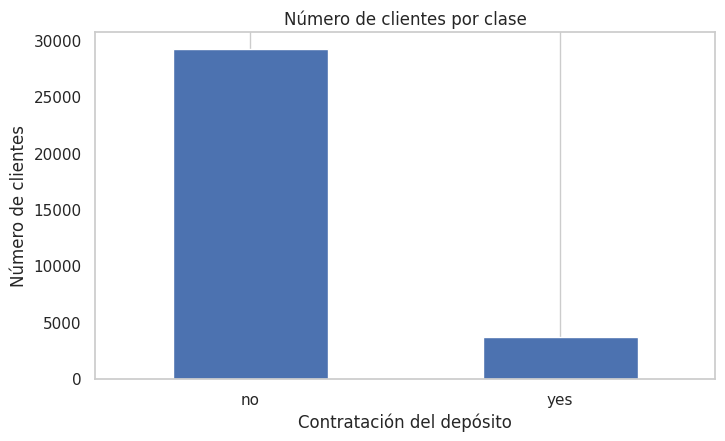

In [9]:
# D1. Escribe el código que muestre:
#  - el número y el porcentaje de clientes de cada clase en ent,
#  - la razón entre la clase mayoritaria y la minoritaria,
#  - la exactitud de responder siempre "no",
#  - una gráfica de barras con el número de clientes por clase.

# 1. Número y porcentaje de clientes por clase
conteo = ent["y"].value_counts()
porcentaje = ent["y"].value_counts(normalize=True) * 100

print("Número de clientes por clase:")
print(conteo)

print("\nPorcentaje de clientes por clase:")
print(porcentaje.round(2))

# 2. Razón entre la clase mayoritaria y la minoritaria
razon = conteo.max() / conteo.min()
print("\nRazón mayoritaria/minoritaria:", round(razon, 2))

# 3. Exactitud de responder siempre "no"
exactitud_no = (ent["y"] == "no").mean() * 100
print("Exactitud de predecir siempre 'no':",
      round(exactitud_no, 2), "%")

# 4. Gráfica de barras
conteo.plot(kind="bar", figsize=(8, 4.5))
plt.title("Número de clientes por clase")
plt.xlabel("Contratación del depósito")
plt.ylabel("Número de clientes")
plt.xticks(rotation=0)
plt.grid(axis="y")
plt.show()

---
---
* El código utiliza `value_counts()` para contrar los clientes de cada clase y value_counts(normalize=True) calcula sus porcentajes. Después, se calcula la razón entre ambas clases y la exactitud de predecir siempre "no", y se representa la distribución con una gráfica de barras.
---
---


**Tu observación.** Compara con tu predicción de las partes A y D y explica qué implica para la evaluación del modelo.

Mi predicción de la parte A fue que aproximadamente el 30 % de los contactos contrataría el depósito, y los resultados muestran que fue cerca del 11.27 %. En la parte D, esperaba que un modelo que siempre respondiera no obtuviera una exactitud de 88.73 %, debido a que la mayoría de los clientes no contrató.
Esto implica que la exactitud por sí sola no es suficiente para evaluar el modelo, ya que podría parecer bueno aunque no identificara a ningún cliente que sí contrataría el depósito. Por eso, también será necesario evaluar métricas como precision, recall y F1-score, que permiten analizar mejor la identificación de la clase minoritaria (yes).


### D2. Variables numéricas según la clase

**Por qué.** Para cada característica numérica interesa cómo se distribuye en cada clase: si lo hace de forma distinta, la variable separa a quienes contratan de quienes no. Se compara la mediana porque es resistente a valores extremos.

**Tu predicción.** ¿Cuáles de las variables numéricas esperas que más difieran entre quienes contratan y quienes no?

Espero que las variables `duration`, `pdays` y `previous` sean las que más difieran entre los clientes que contratan (yes) y los que no (no). En particular, espero que `duration` sea mayor en las llamadas de quienes contratan y que los clientes contactados anteriormente tengan mayor probabilidad de aceptar el depósito.

Mediana de las variables numéricas por clase:
y                     no       yes
age               38.000    37.000
duration         164.000   448.000
campaign           2.000     2.000
pdays            999.000   999.000
previous           0.000     0.000
emp.var.rate       1.100    -1.800
cons.price.idx    93.918    93.200
cons.conf.idx    -41.800   -40.400
euribor3m          4.857     1.266
nr.employed     5195.800  5099.100


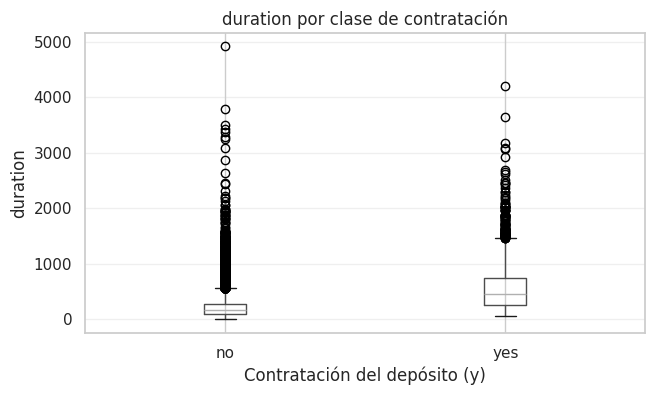

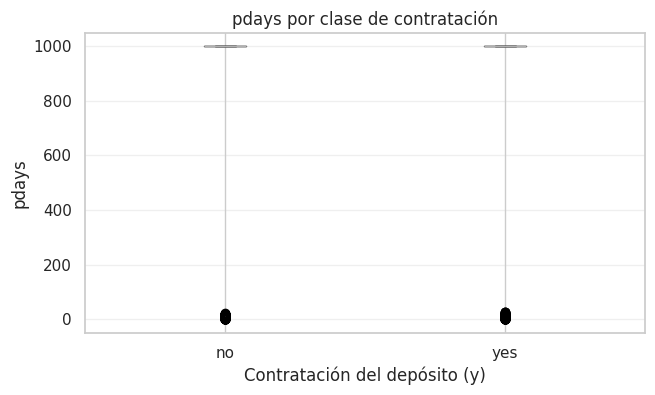

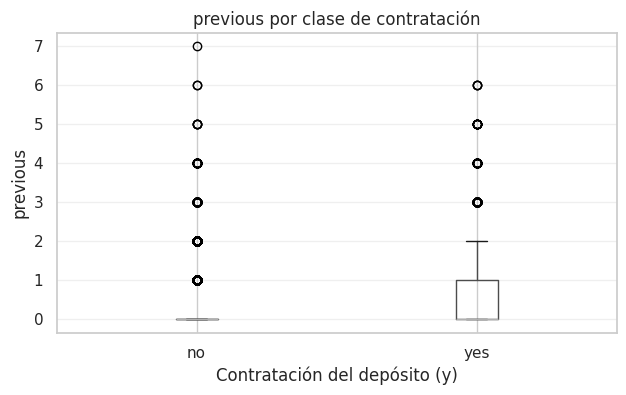

In [10]:
# D2. Escribe el código que muestre:
#  - la mediana de cada variable numérica (lista numericas) por clase de y,
#  - diagramas de caja por clase de y de al menos tres variables numéricas que elijas.


# 1. Lista de variables numéricas
numericas = ent.select_dtypes(include="number").columns.tolist()
numericas = [col for col in numericas if col != "suscribe"]

# 2. Mediana de cada variable numérica por clase de y
print("Mediana de las variables numéricas por clase:")
print(ent.groupby("y")[numericas].median().T)



# 3. Diagramas de caja de tres variables
variables_graficar = ["duration", "pdays", "previous"]

for variable in variables_graficar:
    ent.boxplot(column=variable, by="y", figsize=(7, 4))
    plt.title(f"{variable} por clase de contratación")
    plt.suptitle("")
    plt.xlabel("Contratación del depósito (y)")
    plt.ylabel(variable)
    plt.grid(axis="y", alpha=0.3)
    plt.show()



---
---
* En el código del ejercicio D2 `groupby("y")[numericas].median()` compara las medianas de las variables numéricas entre quienes contrataron y quienes no. Después, los diagramas de caja permiten visualizar las diferencias en la distribución de duration, pdays y previous entre ambas clases.
---
---


**Tu observación.** Indica qué variables separan las clases y cuáles no, con las medianas.


Las variables que más separan las clases son duration, cuya mediana es de 164 segundos para no y 448 para yes, y los indicadores económicos emp.var.rate (1.1 frente a -1.8), euribor3m (4.857 frente a 1.266) y nr.employed (5195.8 frente a 5099.1). En cambio, campaign tiene una mediana de 2 en ambas clases, mientras que pdays (999) y previous (0) tampoco muestran diferencias en sus medianas.
Mi predicción se cumplió parcialmente: esperaba que duration fuera una de las variables con mayor diferencia y que los indicadores económicos influyeran. Sin embargo, pdays y previous no mostraron diferencias en sus medianas. Esto no significa que no aporten información, sino que sus medianas por sí solas no permiten distinguir las clases.

### D3. Valores atípicos

**Por qué.** Los modelos lineales, las máquinas de soporte vectorial y las redes neuronales son sensibles a valores extremos y a la escala; los árboles de decisión y sus conjuntos no lo son. El EDA documenta el problema y la decisión depende del modelo.

Los límites de Tukey (1.5 veces el rango intercuartílico) se calculan con los cuartiles de los datos, por lo que se obtienen con el conjunto de entrenamiento.

**Tu predicción.** ¿Qué variables numéricas esperas que tengan más registros fuera de los límites de Tukey?

Espero que las variables duration, campaign y age tengan más registros fuera de los límites de Tukey, porque pueden presentar valores extremos y distribuciones asimétricas. También espero que previous tenga algunos valores atípicos. En particular, duration podría tener muchas llamadas de duración elevada en comparación con la mayoría de los contactos.

In [11]:
# D3. Escribe el código que calcule, con ent, los límites inferior y superior de Tukey
# de cada variable de la lista numericas y muestre cuántos registros quedan fuera de ellos por variable.

#Calculo de limites inferiores y superiores y RIC
for variable in numericas:
    Q1 = ent[variable].quantile(0.25)
    Q3 = ent[variable].quantile(0.75)
    RIC = Q3 - Q1

    limite_inferior = Q1 - 1.5 * RIC
    limite_superior = Q3 + 1.5 * RIC

    fuera = ((ent[variable] < limite_inferior) | #Deteccion de datos fuera de limites
             (ent[variable] > limite_superior)).sum()

    print(f"{variable}:")
    print(f"  Límite inferior: {limite_inferior:.2f}")
    print(f"  Límite superior: {limite_superior:.2f}")
    print(f"  Registros fuera de los límites: {fuera}")

age:
  Límite inferior: 9.50
  Límite superior: 69.50
  Registros fuera de los límites: 368
duration:
  Límite inferior: -221.00
  Límite superior: 643.00
  Registros fuera de los límites: 2366
campaign:
  Límite inferior: -2.00
  Límite superior: 6.00
  Registros fuera de los límites: 1916
pdays:
  Límite inferior: 999.00
  Límite superior: 999.00
  Registros fuera de los límites: 1226
previous:
  Límite inferior: 0.00
  Límite superior: 0.00
  Registros fuera de los límites: 4534
emp.var.rate:
  Límite inferior: -6.60
  Límite superior: 6.20
  Registros fuera de los límites: 0
cons.price.idx:
  Límite inferior: 91.70
  Límite superior: 95.37
  Registros fuera de los límites: 0
cons.conf.idx:
  Límite inferior: -52.15
  Límite superior: -26.95
  Registros fuera de los límites: 359
euribor3m:
  Límite inferior: -4.08
  Límite superior: 10.39
  Registros fuera de los límites: 0
nr.employed:
  Límite inferior: 4905.60
  Límite superior: 5421.60
  Registros fuera de los límites: 0


---
---
* En el código del ejercicio D3 se utiliza `quantile()` para obtener el primer y tercer cuartil, y con ellos se calcula el rango intercuartílico (RIC). Después se establecen los límites de Tukey y se cuentan los registros que quedan fuera de ellos para cada variable numérica.
---
---

**Tu respuesta.** ¿Eliminarías los registros atípicos de alguna variable? Justifica por variable con lo que sabes de su significado.

No eliminaría automáticamente los registros atípicos, porque algunos son valores válidos según el significado de las variables. En age, los 368 registros fuera de los límites podrían corresponder a clientes mayores de 69 años; en duration, las 2,366 llamadas podrían ser largas, pero válidas; y en campaign, los 1,916 registros podrían representar clientes contactados más de seis veces.
En pdays, los 1,226 registros fuera de los límites corresponden a valores distintos de 999, que representan días desde un contacto anterior; no necesariamente son errores. En previous, los 4,534 registros con valores mayores que cero indican contactos previos, por lo que tampoco los eliminaría. En cons.conf.idx, revisaría los 359 registros porque representan indicadores económicos que podrían ser válidos. Finalmente, no se detectaron valores atípicos en emp.var.rate, cons.price.idx, euribor3m ni nr.employed.
En conclusión, no eliminaría registros únicamente por estar fuera de los límites de Tukey. Primero verificaría si son errores o valores válidos, ya que eliminarlos podría hacer que el modelo perdiera información importante.

### D4. Asimetría y re-expresión

**Por qué.** Cuando una variable tiene asimetría fuerte, una transformación monótona (raíz cuadrada o logaritmo) puede acercar su distribución a una forma simétrica. Un modelo sensible a la escala se beneficia; uno basado en árboles no. La asimetría guía la decisión.

**Tu predicción.** ¿Cuál transformación, raíz cuadrada o logaritmo (`np.log1p`), reducirá más la asimetría de `campaign`?

El logaritmo (np.log1p) reducirá más la asimetría de campaign, porque comprime con mayor intensidad los valores grandes y puede acercar la distribución a una forma más simétrica.

,Variable,Asimetría original,Asimetría raíz cuadrada,Asimetría logarítmica
0,age,0.7608,0.4261,0.1324
1,duration,3.3266,1.2037,-0.4302
2,campaign,4.7425,2.1630,1.3510


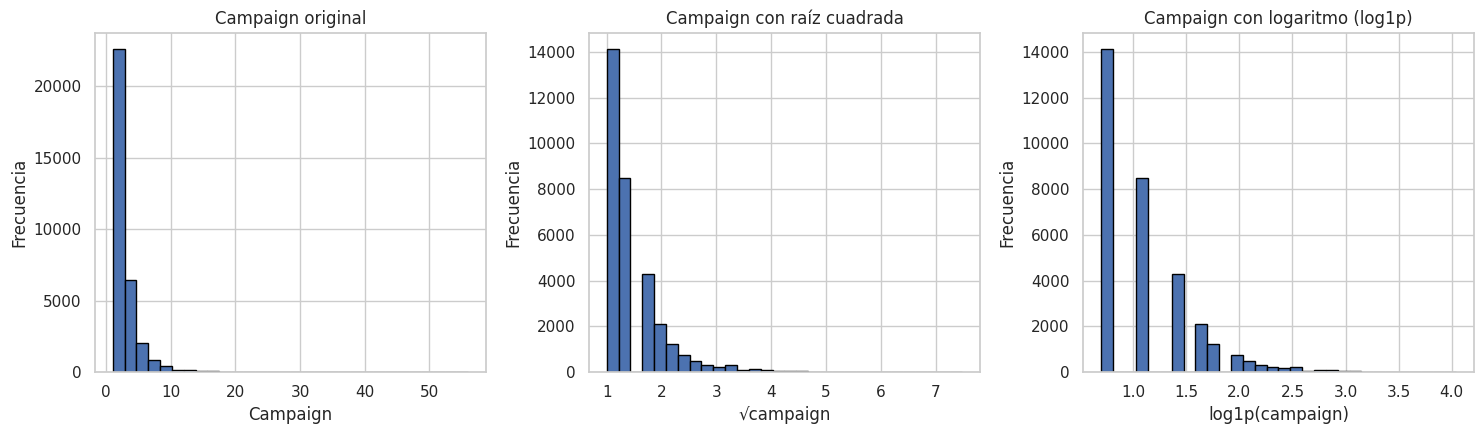

In [12]:
# D4. Escribe el código que muestre una tabla con la asimetría original, con raíz cuadrada y con
# logaritmo (np.log1p) de las variables age, duration y campaign, calculada con ent.
# Después grafica los histogramas de campaign: original y transformada.


#1.  Calcular la asimetría original y transformada
# Variables a analizar
variables = ['age', 'duration', 'campaign']

# Calcular la asimetría
resultados = []

for variable in variables:
    datos = ent[variable].dropna()

    resultados.append({
        'Variable': variable,
        'Asimetría original': datos.skew(),
        'Asimetría raíz cuadrada': np.sqrt(datos).skew(),
        'Asimetría logarítmica': np.log1p(datos).skew()
    })

# Mostrar tabla de resultados
tabla_asimetria = pd.DataFrame(resultados)

display(tabla_asimetria.round(4))


# D4. Histogramas de campaign: original y transformadas

campaign_original = ent['campaign'].dropna()

# Aplicar transformaciones
campaign_raiz = np.sqrt(campaign_original)
campaign_log = np.log1p(campaign_original)

# Crear histogramas
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))

# Histograma original
axes[0].hist(campaign_original, bins=30, edgecolor='black')
axes[0].set_title('Campaign original')
axes[0].set_xlabel('Campaign')
axes[0].set_ylabel('Frecuencia')

# Histograma con raíz cuadrada
axes[1].hist(campaign_raiz, bins=30, edgecolor='black')
axes[1].set_title('Campaign con raíz cuadrada')
axes[1].set_xlabel('√campaign')
axes[1].set_ylabel('Frecuencia')

# Histograma con logaritmo
axes[2].hist(campaign_log, bins=30, edgecolor='black')
axes[2].set_title('Campaign con logaritmo (log1p)')
axes[2].set_xlabel('log1p(campaign)')
axes[2].set_ylabel('Frecuencia')

plt.tight_layout()
plt.show()

---
---
* El código del ejercicio D4 con un `ciclo for` y `.dropna()` recorre las variables y elimina los valores faltantes. Después, calcula la asimetría original y la compara con las transformaciones de raíz cuadrada (`np.sqrt()`) y logaritmo (`np.log1p())`, mostrando los resultados en una tabla redondeada a cuatro decimales. Finalmente, aplica ambas transformaciones a campaign y genera tres histogramas para comparar visualmente la distribución original con las transformadas e identificar cuál reduce más la asimetría.
---
---

**Tu observación.** Reporta las asimetrías y decide qué transformación, si alguna, aplicarías a cada variable.

Las asimetrías obtenidas fueron las siguientes:
* Age: original = 0.7608, raíz cuadrada = 0.4261 y logaritmo = 0.1324. Aplicaría el logaritmo, porque reduce más la asimetría y la acerca a cero.
* Duration: original = 3.3266, raíz cuadrada = 1.2037 y logaritmo = -0.4302. Aplicaría el logaritmo, ya que reduce considerablemente la asimetría, aunque cambia su signo.
* Campaign: original = 4.7425, raíz cuadrada = 2.1630 y logaritmo = 1.3510. Aplicaría el logaritmo, porque logra la mayor reducción de la asimetría, aunque la distribución sigue siendo asimétrica positiva.


Comparación con mi predicción: Mi predicción fue que el logaritmo reduciría más la asimetría de campaign, y los resultados la confirmaron, pues pasó de 4.7425 a 1.3510.

## Parte E. Exploración de las variables categóricas, entrenamiento

**Por qué.** Para una característica categórica, la medida natural es la **tasa de contratación por categoría** comparada con la tasa global, junto con el número de clientes: una tasa calculada con pocos registros es poco confiable.

**Tu predicción.** ¿Qué variable categórica esperas que tenga las categorías con mayor tasa de contratación? ¿Y cuáles esperas que casi no separen las clases?

Espero que la variable poutcome tenga las categorías con mayor tasa de contratación, especialmente success, porque representa resultados exitosos de campañas anteriores. También esperaría que contact y day_of_week separen poco las clases, ya que sus categorías podrían tener tasas de contratación similares.

In [13]:
# E1. Escribe el código que muestre:
#  - el número de categorías de cada variable de la lista categoricas,
#  - la tasa global de contratación en ent.

# Identificar las variables categóricas
categoricas = ent.select_dtypes(include=['object', 'category']).columns

# Número de categorías por variable
print("Número de categorías por variable:")
display(
    ent[categoricas]
    .nunique()
    .sort_values()
    .to_frame(name='Número de categorías')
)

# Tasa global de contratación
tasa_global = (ent['y'] == 'yes').mean() * 100

print(f"Tasa global de contratación: {tasa_global:.2f}%")

Número de categorías por variable:


,Número de categorías
contact,2
y,2
housing,3
default,3
poutcome,3
loan,3
marital,4
day_of_week,5
education,8
month,10


Tasa global de contratación: 11.27%


---
---
* En el código `nunique()` cuenta el número de categorías diferentes de cada variable de la lista categoricas y los resultados se ordenan en una tabla. Después, se calcula la tasa global de contratación contando los registros donde y es igual a 'yes' y se obtiene el porcentaje respecto al total de registros de ent.
---
---

In [14]:
# E2. Escribe el código que construya una tabla con el número de clientes y la tasa de contratación (en %)
# de cada categoría de cada variable de categoricas. Muestra:
#  - las 12 categorías con mayor tasa,
#  - las 8 con menor tasa,
#  - las tablas de default, housing, loan y day_of_week.
# Pista: reutiliza el patrón melt + groupby + agg del notebook guiado del caso Telco.


# Identificar las variables categóricas, excluyendo la variable objetivo
categoricas = ent.select_dtypes(include=['object', 'category']).columns.tolist()
categoricas = [col for col in categoricas if col != 'y']

# Convertir las variables categóricas a formato largo
datos_largos = ent.melt(id_vars='y', value_vars=categoricas, var_name='Variable', value_name='Categoría')

# Calcular el número de clientes y la tasa de contratación
tabla_categorias = (
    datos_largos
    .groupby(['Variable', 'Categoría'], dropna=False)
    .agg(
        clientes=('y', 'size'),
        contrataciones=('y', lambda x: (x == 'yes').sum())
    )
    .reset_index()
)


tabla_categorias['Tasa de contratación (%)'] = (
    tabla_categorias['contrataciones'] / tabla_categorias['clientes'] * 100
)

# Mostrar las 12 categorías con mayor tasa de contratación
print("12 categorías con mayor tasa de contratación:")
display(
    tabla_categorias
    .sort_values('Tasa de contratación (%)', ascending=False)
    .head(12)
    .round(2)
)

# Mostrar las 8 categorías con menor tasa de contratación
print("8 categorías con menor tasa de contratación:")
display(
    tabla_categorias
    .sort_values('Tasa de contratación (%)', ascending=True)
    .head(8)
    .round(2)
)


# Mostrar las tablas de las variables solicitadas
for variable in ['default', 'housing', 'loan', 'day_of_week']:
    print(f"\nTabla de {variable}:")
    display(
        tabla_categorias[tabla_categorias['Variable'] == variable]
        [['Categoría', 'clientes', 'contrataciones', 'Tasa de contratación (%)']]
        .sort_values('Tasa de contratación (%)', ascending=False)
        .round(2)
        .reset_index(drop=True)
    )

12 categorías con mayor tasa de contratación:


,Variable,Categoría,clientes,contrataciones,Tasa de contratación (%)
52,poutcome,success,1105,717,64.89
42,month,dec,143,72,50.35
45,month,mar,436,217,49.77
49,month,sep,464,207,44.61
48,month,oct,587,254,43.27
29,job,student,711,217,30.52
26,job,retired,1366,348,25.48
40,month,apr,2085,427,20.48
14,education,illiterate,16,3,18.75
39,marital,unknown,65,11,16.92


8 categorías con menor tasa de contratación:


,Variable,Categoría,clientes,contrataciones,Tasa de contratación (%)
9,default,yes,3,0,0.00
8,default,unknown,6940,361,5.20
1,contact,telephone,12042,638,5.30
46,month,may,11011,699,6.35
22,job,blue-collar,7441,515,6.92
12,education,basic.9y,4826,369,7.65
28,job,services,3196,254,7.95
11,education,basic.6y,1865,156,8.36



Tabla de default:


...

,Categoría,clientes,contrataciones,Tasa de contratación (%)
0,yes,17254,1994,11.56
1,unknown,796,90,11.31
2,no,14900,1628,10.93



Tabla de loan:


,Categoría,clientes,contrataciones,Tasa de contratación (%)
0,unknown,796,90,11.31
1,no,27131,3058,11.27
2,yes,5023,564,11.23



Tabla de day_of_week:


,Categoría,clientes,contrataciones,Tasa de contratación (%)
0,thu,6857,823,12.00
1,tue,6444,748,11.61
2,wed,6515,753,11.56
3,fri,6322,690,10.91
4,mon,6812,698,10.25


---
---
* En el código melt() reúne las variables categóricas en una sola columna para analizarlas de manera conjunta. Después, groupby() y agg() agrupan los clientes por variable y categoría, cuentan cuántos hay y cuántos contrataron. Con esos datos calculo la tasa de contratación en porcentaje y ordeno los resultados para identificar las categorías con tasas más altas y más bajas, además de mostrar las tablas específicas solicitadas.
---
---

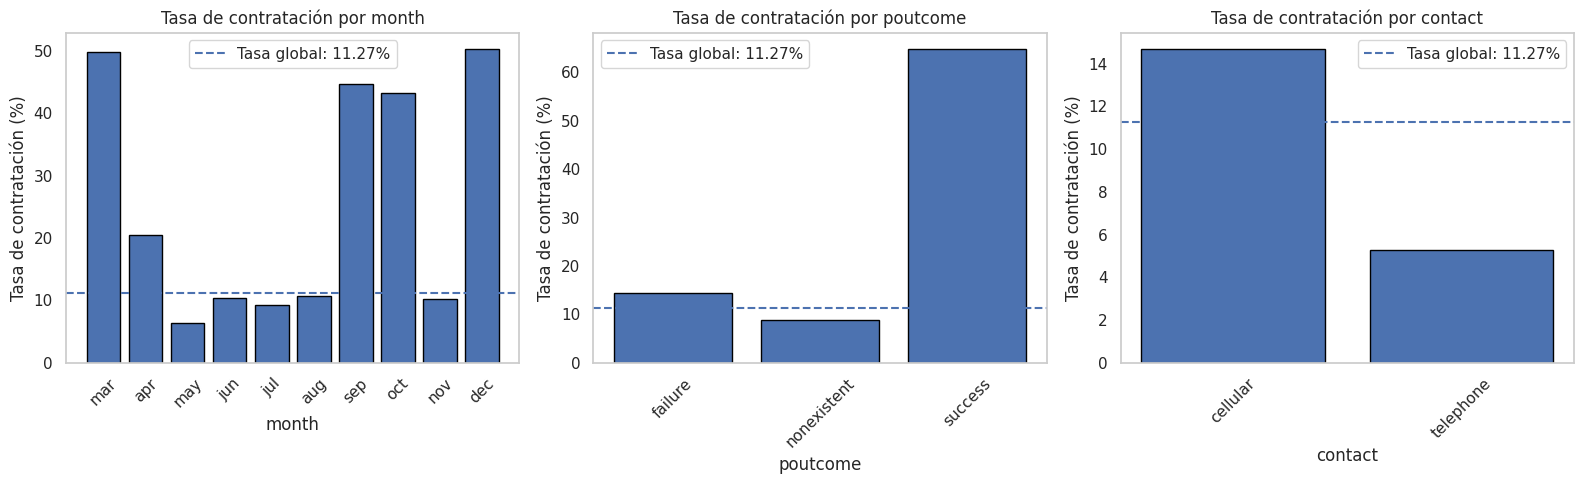

In [15]:
# E3. Escribe el código que grafique la tasa de contratación por categoría de month (en orden
# cronológico: mar, apr, may, jun, jul, aug, sep, oct, nov, dec), poutcome y contact,
# con una línea horizontal en la tasa global.

# Tasa global de contratación
tasa_global = (ent['y'] == 'yes').mean() * 100

# Orden cronológico de los meses
orden_meses = ['mar', 'apr', 'may', 'jun', 'jul', 'aug', 'sep', 'oct', 'nov', 'dec']

# Variables a graficar
variables = ['month', 'poutcome', 'contact']

# Crear una gráfica para cada variable
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

for ax, variable in zip(axes, variables):

    # Calcular la tasa de contratación por categoría
    tasas = (ent.groupby(variable, observed=False)['y'] .apply(lambda x: (x == 'yes').mean() * 100))

    # Ordenar los meses cronológicamente
    if variable == 'month':
        tasas = tasas.reindex(orden_meses)

    # Graficar las tasas
    ax.bar(tasas.index.astype(str), tasas.values, edgecolor='black')

    # Línea horizontal de la tasa global
    ax.axhline(
        tasa_global,
        linestyle='--',
        linewidth=1.5,
        label=f'Tasa global: {tasa_global:.2f}%'
    )

    ax.set_title(f'Tasa de contratación por {variable}')
    ax.set_xlabel(variable)
    ax.set_ylabel('Tasa de contratación (%)')
    ax.tick_params(axis='x', rotation=45)
    ax.legend()
    ax.grid(False)

plt.tight_layout()
plt.show()

---
---
* En el código agrupo los clientes por categoría de cada variable y calculo el porcentaje que contrató. Después, genero una gráfica para month, poutcome y contact, ordenando los meses cronológicamente. Finalmente, agrego una línea horizontal con la tasa global de contratación para identificar qué categorías tienen tasas superiores o inferiores al promedio.
---
---

**Tu observación.** Identifica las categorías con mayor y menor tasa, con su tasa y su número de clientes, y las variables que casi no separan las clases.

Las categorías con mayor tasa de contratación fueron poutcome = success, con 64.89 % de 1,105 clientes, seguida de month = dec, con 50.35 % de 143 clientes, y month = mar, con 49.77 % de 436 clientes. También destacan month = sep (44.61 %, 464 clientes) y month = oct (43.27 %, 587 clientes).
Por otro lado, las menores tasas se encontraron en default = yes, con 0 % de 3 clientes; default = unknown, con 5.20 % de 6,940 clientes; y contact = telephone, con 5.30 % de 12,042 clientes. También destacan month = may (6.35 %, 11,011 clientes) y job = blue-collar (6.92 %, 7,441 clientes).
Las variables que casi no separan las clases son loan, cuyas tasas van de 11.23 % a 11.31 %; housing, con tasas de 10.93 % a 11.56 %; y day_of_week, cuyas tasas van de 10.25 % a 12.00 %. Sus tasas son relativamente similares entre categorías, por lo que parecen aportar poca separación por sí solas. En default, la categoría yes tiene solo tres clientes, así que su tasa de 0 % debe interpretarse con precaución.
Comparación con mi predicción: acerté al anticipar que poutcome, especialmente success, tendría una tasa de contratación alta. Sin embargo, contact sí muestra una diferencia importante entre categorías: cellular tiene una tasa de 14.70 %, frente a 5.30 % de telephone. Las tablas también muestran que day_of_week y loan separan poco las clases, como esperaba.

**Tu respuesta.** En `default`, ¿qué indica que la categoría `unknown` tenga una tasa de contratación distinta a la de `no`? ¿Qué hay que cuidar con las categorías `yes` de `default` o `illiterate` de `education`?

En default, la categoría unknown tiene una tasa de contratación de 5.20 %, mientras que no tiene 12.88 %. Esto indica que los clientes cuyo estado de incumplimiento se desconoce presentan una tasa de contratación menor que aquellos que no tienen incumplimientos registrados. Sin embargo, esto no significa que desconocer el dato sea la causa de la diferencia.
Hay que tener cuidado con las categorías que tienen pocos clientes, como yes en default, que solo tiene 3 clientes, e illiterate en education, que tiene 16. Sus tasas pueden ser poco representativas y variar mucho debido al tamaño reducido de la muestra, por lo que no conviene sacar conclusiones generales sin considerar esta limitación.

## Parte F. Relaciones entre características y variable `duration`, entrenamiento

### F1. Relaciones entre características

**Por qué.** Dos características muy relacionadas son redundantes y pueden causar inestabilidad en modelos lineales (colinealidad).

**Tu predicción.** ¿Qué pares de indicadores económicos (lista `macro`) esperas que estén más correlacionados?

Espero que euribor3m y emp.var.rate estén fuertemente correlacionados, porque ambos reflejan condiciones económicas y tasas de interés. También espero una correlación alta entre nr.employed y euribor3m, así como entre nr.employed y emp.var.rate, ya que pueden variar conjuntamente según la situación económica y laboral.

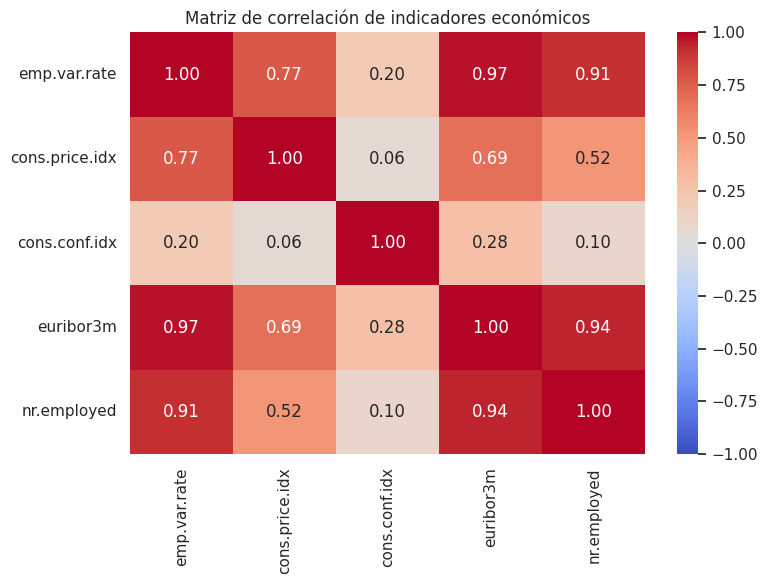

In [16]:
# F1. Escribe el código que muestre un mapa de calor con la matriz de correlación de las variables de la lista macro,
# calculada con ent, con los valores anotados en cada celda.

# Calcular la matriz de correlación
correlacion = ent[macro].corr()

# Crear el mapa de calor
plt.figure(figsize=(8, 6))
sns.heatmap(
    correlacion,
    annot=True,
    fmt='.2f',
    cmap='coolwarm',
    vmin=-1,
    vmax=1
)

plt.title('Matriz de correlación de indicadores económicos')
plt.tight_layout()
plt.show()

**Tu observación.** Reporta los pares más correlacionados y la decisión que implican.

Los pares más correlacionados fueron euribor3m con emp.var.rate (0.97) y nr.employed con euribor3m (0.94), lo que indica una relación positiva muy fuerte. Por otro lado, las correlaciones más bajas fueron cons.price.idx con cons.conf.idx (0.06) y cons.conf.idx con nr.employed (0.10), lo que indica una relación lineal muy débil.
Decisión: consideraría conservar solo uno de los indicadores que presentan correlaciones muy altas, como euribor3m y emp.var.rate, para evitar información redundante en algunos modelos. Los indicadores con correlaciones bajas podrían aportar información diferente, por lo que no los descartaría únicamente por estos resultados.
Comparación con mi predicción: mi predicción fue acertada, porque esperaba una correlación alta entre euribor3m, emp.var.rate y nr.employed. Los resultados del mapa de calor lo confirmaron.

### F2. La variable `duration`

**Por qué.** Una variable puede tener una relación muy fuerte con el objetivo y aun así no ser utilizable. Esto ocurre cuando su valor solo se conoce después del evento que se quiere predecir.

In [17]:
# F2. Escribe el código que muestre el resumen estadístico (describe) de duration por clase de y.

display(ent.groupby('y')['duration'].describe())

,count,mean,std,min,25%,50%,75%,max
y,,,,,,,,
no,29238.0,221.148198,208.303557,0.0,95.0,164.0,279.0,4918.0
yes,3712.0,549.398976,397.490060,63.0,252.0,448.0,737.0,4199.0


---
---
* En el código del ejercicio F2 groupby('y') separa los clientes según la clase de contratación (yes o no) y describe() calcula las estadísticas descriptivas de duration para cada grupo, como el número de registros, la media, la desviación estándar, los valores mínimo y máximo y los cuartiles.
---
---

**Tu respuesta.** ¿Incluirías `duration` como característica de un modelo que se usará para decidir a quién llamar? Justifica con la definición de la variable y con lo observado.

No incluiría `duration` como característica de un modelo que se utilizará para decidir a quién llamar, porque representa la duración de la llamada en segundos y solo se conoce una vez que la llamada ha terminado. Aunque las estadísticas muestran diferencias entre los clientes que contrataron y los que no, utilizar esta variable para decidir a quién contactar generaría fuga de información, ya que no estaría disponible antes de realizar la llamada.

**Tu respuesta.** El conjunto está ordenado por fecha y los indicadores económicos varían con el tiempo. ¿Qué implica dividir al azar, como en la parte C, para un modelo que se usará en campañas futuras?

Dividir los datos al azar puede hacer que el modelo se entrene con registros de fechas posteriores a los que aparecen en la prueba. Esto puede generar una evaluación demasiado optimista, porque el modelo estaría aprendiendo de condiciones económicas futuras. Para simular mejor su uso en campañas futuras, conviene entrenarlo con los datos más antiguos y evaluarlo con los más recientes, respetando el orden temporal.

## Parte G. Hoja de decisiones y justificación del uso de los datos

### G1. Hoja de decisiones

**Por qué.** El producto de un EDA predictivo es una lista de decisiones, cada una con su evidencia. Ninguna decisión se aplica todavía sobre los datos.

Completa la tabla con **al menos siete decisiones**, cada una con un hallazgo de tu análisis (con su cifra), la decisión y el tema del curso donde se aplicaría (preprocesamiento, modelos, evaluación). Debe aparecer al menos una decisión sobre cada uno de estos aspectos: variable no utilizable, valores faltantes o códigos especiales, desbalance de clases, redundancia entre características y asimetría.

Edita esta celda y agrega las filas que necesites.

| Hallazgo (con cifra) | Decisión | Se aplica en |
| --- | --- | --- |
| `duration` representa la duración de la llamada y solo se conoce después de realizarla. Se observaron diferencias en su distribución entre clientes que contrataron y los que no.|Excluir `duration` del modelo destinado a decidir a quién llamar, para evitar fuga de información. |Preprocesamiento |
| En `default`, la categoría unknown contiene 6,940 clientes, mientras que la categoría yes solo contiene 3.|Conservar los valores desconocidos como categoría o tratarlos explícitamente; revisar la categoría yes por su tamaño reducido antes de modelar.| Preprocesamiento|
| La tasa global de contratación es de aproximadamente 11.27%, frente a 88.73% de clientes que no contrataron.|Evaluar métricas como precision, recall, F1 y matriz de confusión, además de la exactitud; considerar técnicas para manejar el desbalance si resulta necesario. |Evaluación / Modelos |
|`euribor3m` y `emp.var.rate` presentan una correlación de 0.97; `euribor3m` y `nr.employed`, de 0.94. |Revisar la redundancia y comparar modelos con y sin algunos de estos indicadores, especialmente si se utiliza un modelo sensible a la multicolinealidad. | Preprocesamiento / Modelos|
|La asimetría de `campaign `disminuye de 4.7425 en su escala original a 1.3510 después de aplicar `log1p.` |Evaluar una transformación logarítmica para reducir la asimetría y comparar su efecto en el desempeño del modelo. |Preprocesamiento |
| La tasa de contratación es de 64.89% para poutcome = success (717 de 1,105 clientes), frente a una tasa global cercana al 11.27%.|Comparar modelos que utilicen el resultado de campañas anteriores y verificar que esta información esté disponible al momento de tomar la decisión. | Preprocesamiento / Modelos|
|La tasa de contratación es de 14.70% para `contact = cellular` y de 5.30% para `contact = telephone `|Conservar inicialmente `contact` como característica candidata y evaluar su utilidad predictiva; verificar también que el tipo de contacto sea conocido antes de seleccionar a quién llamar. | Modelos|
|Los registros están ordenados por fecha y los indicadores económicos cambian con el tiempo. Una división aleatoria podría mezclar registros anteriores y posteriores. |Comparar la evaluación aleatoria con una división temporal: entrenar con fechas anteriores y evaluar con las más recientes. | Evaluación|

### G2. Uso de los datos

**Tu respuesta.** En esta actividad, ¿qué partes se hicieron con el conjunto total y cuáles solo con entrenamiento? Explica el criterio.

El análisis exploratorio de datos (EDA), como revisar distribuciones, calcular estadísticas descriptivas, identificar valores faltantes y analizar correlaciones, se realizó con el conjunto de datos completo para comprender sus características. En cambio, las operaciones que preparan los datos para entrenar el modelo, como calcular parámetros de imputación, escalado o selección de características, deben ajustarse únicamente con el conjunto de entrenamiento y después aplicarse al conjunto de prueba. El criterio es evitar la fuga de información y obtener una evaluación más realista del desempeño del modelo con datos nuevos.

**Tu respuesta.** Si hubieras explorado también el conjunto de prueba, ¿qué decisión de tu hoja podría quedar sesgada y cómo se reflejaría en la evaluación final?

La decisión sobre qué características conservar o transformar, por ejemplo, aplicar logaritmo a campaign para reducir su asimetría, podría quedar sesgada si también se explora el conjunto de prueba y se elige la transformación según sus resultados. Esto provocaría fuga de información y la evaluación final podría mostrar un desempeño mejor de lo que realmente tendría el modelo con datos nuevos.